# Solutions to the exercises of Chapter 7

Sample solutions for [Chapter 7, Boundary layers and external flow](../../notebooks/part2_convection/07_boundary_layers.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import convection_ext, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_ext, properties, reference
from engtransport.plotting import use_style

use_style()

## Exercise 1. Wind chill

The heat crosses the tissue and then the outer film in series, so
$q'' = (34\ {\rm °C} - T_{\rm air})/(R''_t + 1/h)$, with $h$ from Eq. (7.8) for a cylinder
0.18 m across. The skin surface is at $34\ {\rm °C} - q''R''_t$.

In [2]:
air = properties.dry_air_properties(265.0)           # film temperature, roughly
D_face, R_tissue, T_core, T_cold = 0.18, 0.1, 34.0, -20.0
h_face = lambda V: convection_ext.nu_cylinder_churchill_bernstein(V * D_face / air["nu"], air["Pr"]) * air["k"] / D_face
for V in (1.34, 5.0, 15.0):
    q = (T_core - T_cold) / (R_tissue + 1 / h_face(V))
    print(f"wind {V:5.2f} m/s: h = {h_face(V):4.1f} W/(m2 K), loss {q:3.0f} W/m2, skin at {T_core - q * R_tissue:5.1f} C")
for V in (5.0, 15.0):
    q = (T_core - T_cold) / (R_tissue + 1 / h_face(V))
    T_equiv = T_core - q * (R_tissue + 1 / h_face(1.34))
    print(f"-20 C at {V:4.0f} m/s feels like {T_equiv:5.1f} C at walking speed")

wind  1.34 m/s: h = 10.2 W/(m2 K), loss 273 W/m2, skin at   6.7 C
wind  5.00 m/s: h = 22.7 W/(m2 K), loss 375 W/m2, skin at  -3.5 C
wind 15.00 m/s: h = 48.4 W/(m2 K), loss 447 W/m2, skin at -10.7 C
-20 C at    5 m/s feels like -40.3 C at walking speed
-20 C at   15 m/s feels like -54.6 C at walking speed


Walking in calm air at −20 °C, the face loses 270 W/m² and its skin stays near 7 °C. In a
5 m/s wind the loss rises by 37 % and the skin falls below 0 °C, which is where frostbite
starts; at 15 m/s it is at −11 °C. To lose heat as fast at walking speed, the air would
have to be at −40 °C and −55 °C. The official wind-chill index rests on the same idea,
with a more careful model of the face and the tissue; this crude version exaggerates, but
it shows why: the outer film is a large part of the resistance of exposed skin, and the
wind thins it.

## Exercise 2. A solar panel

The panel must lose by convection the sunlight it absorbs but does not convert,
$0.8 \times 700 = 560$ W/m².

In [3]:
air_film = properties.dry_air_properties(313.0)
L, U, q_abs = 1.6, 3.0, 0.8 * 700.0
Re_L = U * L / air_film["nu"]
Pr = air_film["Pr"]
h_lam = 0.664 * Re_L**0.5 * Pr ** (1 / 3) * air_film["k"] / L
h_turb = 0.037 * Re_L**0.8 * Pr ** (1 / 3) * air_film["k"] / L
print(f"Re_L = {Re_L:.0f} (below the 5e5 of Eq. (7.7))")
print(f"laminar: h = {h_lam:.1f} W/(m2 K), panel at {20 + q_abs / h_lam:.0f} C")
print(f"turbulent from the edge: h = {h_turb:.1f} W/(m2 K), panel at {20 + q_abs / h_turb:.0f} C")

Re_L = 282516 (below the 5e5 of Eq. (7.7))
laminar: h = 5.4 W/(m2 K), panel at 124 C
turbulent from the edge: h = 12.9 W/(m2 K), panel at 63 C


$\mathrm{Re}_L = 2.8 \times 10^5$ is below the transition of Eq. (7.7), so the mixed formula
reduces to the laminar one, which predicts a panel at 124 °C. A layer turbulent from the
edge gives 63 °C. Outdoors, with a gusty wind, a frame at the edge and a rough surface,
the turbulent value is the better guess; measured panel temperatures in sunshine are
typically 45–60 °C, because the back face and radiation to the sky also cool the panel,
which this exercise left out.

## Exercise 3. Liquid metal

In [4]:
Pr_na = 0.005
exact = convection_ext.pohlhausen_heat_transfer(Pr_na)
fit = 0.332 * Pr_na ** (1 / 3)
small = 0.564 * Pr_na**0.5
print(f"exact {exact:.4f}; 0.332 Pr^1/3 {fit:.4f} ({fit / exact - 1:+.0%}); 0.564 Pr^1/2 {small:.4f} ({small / exact - 1:+.0%})")

exact 0.0374; 0.332 Pr^1/3 0.0568 (+52%); 0.564 Pr^1/2 0.0399 (+7%)


For sodium the familiar formula overestimates the heat transfer by half, while the small-Pr
form is within 7 %. With $\mathrm{Pr} = 0.005$ heat diffuses 200 times faster than momentum,
so the thermal layer is about $\mathrm{Pr}^{-1/2} \approx 14$ times thicker than the velocity
layer. Almost all of it lies in the outer flow, which moves at nearly $U$: the
temperature field is that of a uniform flow past a heated wall, $f = \eta$, which gives
$\theta'(0) = \sqrt{\mathrm{Pr}/\pi} = 0.564\,\mathrm{Pr}^{1/2}$. The $\mathrm{Pr}^{1/3}$ law
assumes the opposite, a thermal layer inside the region where the velocity grows linearly.

## Exercise 4. An unheated starting length

x = 0.35 L: marching 0.6313, classical formula 0.6128 (-2.9%)
x = 0.40 L: marching 0.5235, classical formula 0.5106 (-2.5%)
x = 0.60 L: marching 0.4035, classical formula 0.3968 (-1.7%)
x = 1.00 L: marching 0.3535, classical formula 0.3498 (-1.0%)


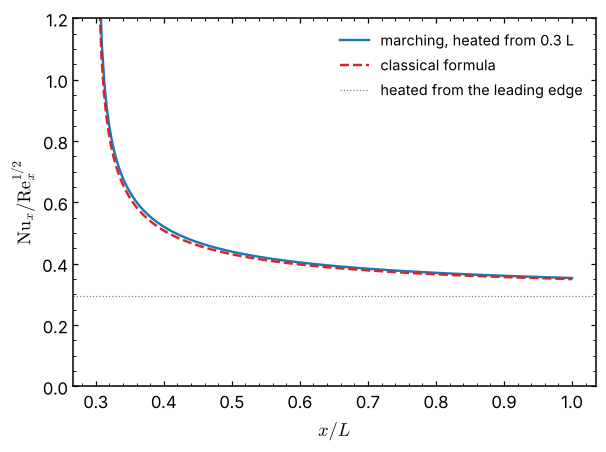

In [5]:
march = reference.boundary_layer_march(0.71, n_x=800, n_y=300, x_heat_start=0.3)
x = march["x"]
uniform = convection_ext.pohlhausen_heat_transfer(0.71)
classical = lambda xx: uniform / (1 - (0.3 / xx) ** 0.75) ** (1 / 3)
for xx in (0.35, 0.4, 0.6, 1.0):
    i = int(np.argmin(np.abs(x - xx)))
    print(f"x = {x[i]:.2f} L: marching {march['Nu_sqrtRe'][i]:.4f}, classical formula {classical(x[i]):.4f}"
          f" ({classical(x[i]) / march['Nu_sqrtRe'][i] - 1:+.1%})")

fig, ax = plt.subplots(figsize=(5.4, 4.0))
heated = x > 0.3
ax.plot(x[heated], march["Nu_sqrtRe"][heated], "C0", label="marching, heated from 0.3 L")
xx = np.linspace(0.305, 1.0, 200)
ax.plot(xx, classical(xx), "C3--", label="classical formula")
ax.axhline(uniform, color="0.5", lw=0.8, ls=":", label="heated from the leading edge")
ax.set_xlabel("$x/L$")
ax.set_ylabel(r"$\mathrm{Nu}_x/\mathrm{Re}_x^{1/2}$")
ax.set_ylim(0, 1.2)
ax.legend(loc="upper right")
plt.show()

**Figure S7.1.** Local heat transfer of a laminar flat plate heated only beyond $x_0 = 0.3L$,
from the marching solution and the classical formula, Pr = 0.71.

Just after the heating starts, the thermal layer is new and very thin inside a velocity
layer that is already thick, so the heat transfer is large; it then falls towards the
value of a plate heated from its leading edge. The classical formula comes from an
approximate integral method and agrees with the marching solution to 1–3 %.